In [1]:

# Cell 1 - Persiapan library dan konfigurasi

!pip -q install kagglehub PyWavelets opencv-python-headless

import os
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import kagglehub
import pywt

from PIL import Image, ImageFile
from IPython.display import display

# Supaya hasil eksperimen lebih konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Pengaturan eksperimen
TEST_SIZE = 0.20
CV_FOLDS = 5

# Format gambar yang akan diperiksa
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("Persiapan selesai.")
print("Seed:", SEED)
print("Proporsi data test:", TEST_SIZE)
print("Jumlah fold cross-validation:", CV_FOLDS)
print("Versi OpenCV:", cv2.__version__)
print("Versi PyWavelets:", pywt.__version__)


Persiapan selesai.
Seed: 42
Proporsi data test: 0.2
Jumlah fold cross-validation: 5
Versi OpenCV: 4.14.0
Versi PyWavelets: 1.8.0


100%|██████████| 5.11G/5.11G [00:53<00:00, 103MB/s]

Extracting files...


Lokasi dataset: /root/.cache/kagglehub/datasets/ndisan/corn-leaf-disease/versions/1

Total file gambar: 4000

STRUKTUR FOLDER DATASET
./ (0 gambar langsung)
    Hawar Daun/ (1000 gambar langsung)
    Bercak Daun/ (1000 gambar langsung)
    Karat Daun/ (1000 gambar langsung)
    Daun Sehat/ (1000 gambar langsung)

Jumlah gambar berdasarkan folder induk:


,jumlah_gambar
folder_induk,
Bercak Daun,1000
Daun Sehat,1000
Hawar Daun,1000
Karat Daun,1000



Jumlah gambar berdasarkan folder level 2:


...

,jumlah
status,
OK,4000



Statistik dimensi gambar valid:


,lebar,tinggi
count,4000.00,4000.00
mean,2523.67,3080.72
std,1330.95,1649.07
min,200.00,191.00
25%,3120.00,3120.00
50%,3120.00,4160.00
75%,3120.00,4160.00
max,5184.00,4160.00



10 kombinasi resolusi yang paling sering muncul:


,,jumlah
lebar,tinggi,
3120,4160,2578
256,256,926
4160,3120,422
480,320,6
3264,2448,4
1200,630,3
350,230,2
432,324,2
390,259,2


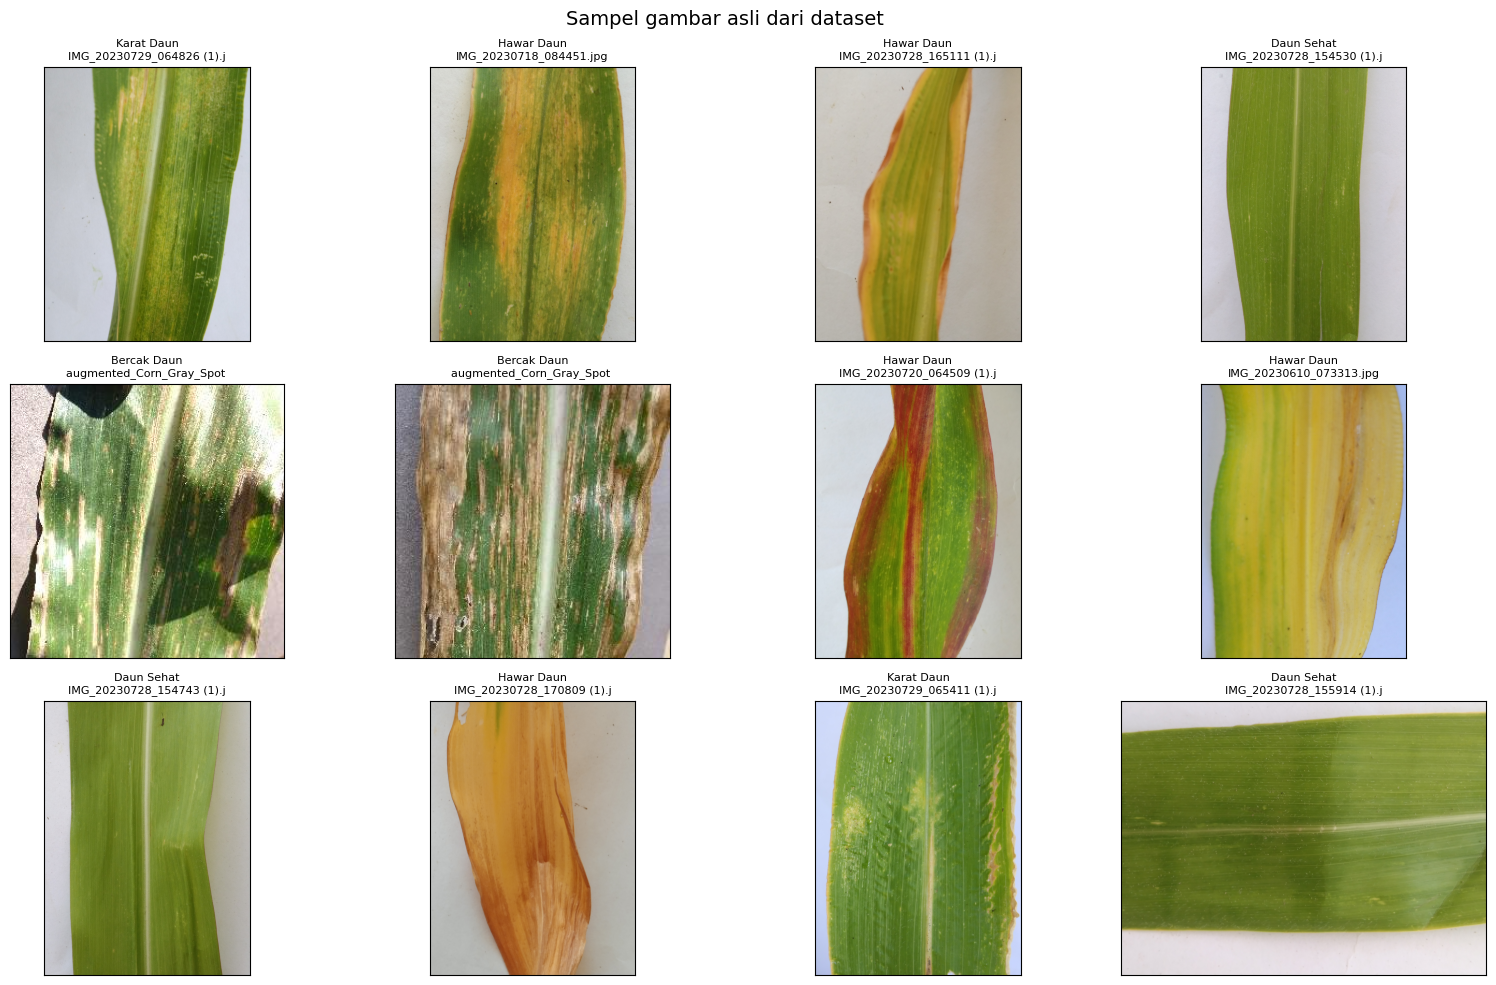

In [2]:

# Cell 2 - Download dan pemeriksaan awal dataset

dataset_path = kagglehub.dataset_download("ndisan/corn-leaf-disease")

print("Lokasi dataset:", dataset_path)

# Mengumpulkan semua file gambar
image_paths = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if Path(file).suffix.lower() in IMAGE_EXTENSIONS:
            image_paths.append(os.path.join(root, file))

print("\nTotal file gambar:", len(image_paths))

if len(image_paths) == 0:
    raise ValueError("Tidak ditemukan gambar. Periksa lokasi dataset.")

# Melihat struktur folder sampai kedalaman 3 tingkat
print("\nSTRUKTUR FOLDER DATASET")

root_path = Path(dataset_path)

for root, dirs, files in os.walk(dataset_path):
    relative_path = Path(root).relative_to(root_path)
    depth = len(relative_path.parts)

    if depth > 3:
        dirs[:] = []
        continue

    jumlah_gambar = sum(
        1 for file in files
        if Path(file).suffix.lower() in IMAGE_EXTENSIONS
    )

    indent = "    " * depth
    print(f"{indent}{relative_path if depth > 0 else '.'}/ "
          f"({jumlah_gambar} gambar langsung)")

# Menghitung jumlah gambar berdasarkan folder
data_folder = []

for path in image_paths:
    p = Path(path)

    data_folder.append({
        "folder_induk": p.parent.name,
        "folder_level_2": p.parent.parent.name,
        "nama_file": p.name,
        "format": p.suffix.lower(),
        "path": str(p)
    })

df_folder = pd.DataFrame(data_folder)

print("\nJumlah gambar berdasarkan folder induk:")
display(
    df_folder.groupby("folder_induk")
    .size()
    .sort_values(ascending=False)
    .rename("jumlah_gambar")
    .to_frame()
)

print("\nJumlah gambar berdasarkan folder level 2:")
display(
    df_folder.groupby("folder_level_2")
    .size()
    .sort_values(ascending=False)
    .rename("jumlah_gambar")
    .to_frame()
)

print("\nDistribusi format file:")
display(
    df_folder["format"]
    .value_counts()
    .rename_axis("format")
    .to_frame("jumlah")
)

# Memeriksa dimensi dan apakah gambar dapat dibaca
data_gambar = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            width, height = img.size
            img.verify()

        data_gambar.append({
            "path": path,
            "lebar": width,
            "tinggi": height,
            "status": "OK"
        })

    except Exception as e:
        data_gambar.append({
            "path": path,
            "lebar": None,
            "tinggi": None,
            "status": "Rusak/tidak terbaca"
        })

df_gambar = pd.DataFrame(data_gambar)

print("\nStatus file gambar:")
display(df_gambar["status"].value_counts().to_frame("jumlah"))

gambar_valid = df_gambar[df_gambar["status"] == "OK"]

print("\nStatistik dimensi gambar valid:")
display(
    gambar_valid[["lebar", "tinggi"]]
    .describe()
    .round(2)
)

print("\n10 kombinasi resolusi yang paling sering muncul:")
display(
    gambar_valid.groupby(["lebar", "tinggi"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("jumlah")
    .to_frame()
)

# Visualisasi sampel gambar asli
jumlah_sampel = min(12, len(image_paths))
sampel_paths = random.sample(image_paths, jumlah_sampel)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, path in zip(axes, sampel_paths):
    try:
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{Path(path).parent.name}\n"
            f"{Path(path).name[:25]}",
            fontsize=8
        )
        ax.axis("on")
        ax.set_xticks([])
        ax.set_yticks([])

    except Exception:
        ax.set_title("Gambar tidak terbaca")

plt.suptitle("Sampel gambar asli dari dataset", fontsize=14)
plt.tight_layout()
plt.show()

1. Dataset seimbang berdasarkan kelas. Setiap kelas memiliki 1.000 gambar.

2. Sebanyak 2.578 gambar berukuran 3120 × 4160 dan 926 gambar berukuran 256 × 256. keduanya mencakup 3.504 gambar atau 87,6% dari seluruh dataset.

3. Sebanyak 422 gambar memiliki resolusi 4160 × 3120, yang merupakan orientasi kebalikan dari resolusi dominan.

4. Pada sampel gambar, sebagian daun difoto dengan latar putih atau abu-abu terang, sedangkan sebagian lainnya memiliki pencahayaan, bayangan, dan kondisi latar yang berbeda. Ada juga gambar daun yang mengisi hampir seluruh bidang gambar.

5. Semua file terdeteksi sebagai JPG.

Jumlah gambar setiap resolusi:


,jumlah
resolusi,
3120x4160,2578
256x256,926
4160x3120,422
Resolusi lainnya,74



Distribusi resolusi untuk setiap kelas:


resolusi,256x256,3120x4160,4160x3120,Resolusi lainnya
folder_induk,,,,
Bercak Daun,926,0,0,74
Daun Sehat,0,757,243,0
Hawar Daun,0,928,72,0
Karat Daun,0,893,107,0



Persentase resolusi dalam setiap kelas:


resolusi,256x256,3120x4160,4160x3120,Resolusi lainnya
folder_induk,,,,
Bercak Daun,92.6,0.0,0.0,7.4
Daun Sehat,0.0,75.7,24.3,0.0
Hawar Daun,0.0,92.8,7.2,0.0
Karat Daun,0.0,89.3,10.7,0.0


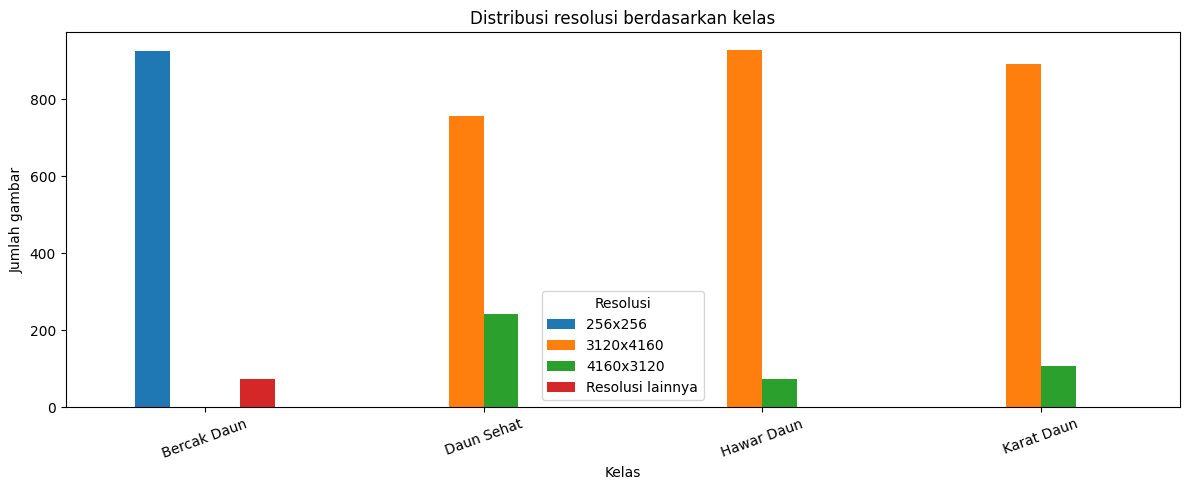

In [3]:

# Cell 3.1 - Analisis resolusi berdasarkan kelas

# Menggabungkan informasi folder kelas dengan dimensi gambar
df_audit = df_gambar.merge(
    df_folder[["path", "folder_induk", "nama_file"]],
    on="path",
    how="left"
)

df_audit = df_audit[df_audit["status"] == "OK"].copy()

# Membuat label resolusi untuk memudahkan analisis
def kelompok_resolusi(row):
    w = row["lebar"]
    h = row["tinggi"]

    if w == 256 and h == 256:
        return "256x256"

    elif w == 3120 and h == 4160:
        return "3120x4160"

    elif w == 4160 and h == 3120:
        return "4160x3120"

    else:
        return "Resolusi lainnya"


df_audit["resolusi"] = df_audit.apply(
    kelompok_resolusi,
    axis=1
)

print("Jumlah gambar setiap resolusi:")
display(
    df_audit["resolusi"]
    .value_counts()
    .rename_axis("resolusi")
    .to_frame("jumlah")
)

print("\nDistribusi resolusi untuk setiap kelas:")
tabel_resolusi = pd.crosstab(
    df_audit["folder_induk"],
    df_audit["resolusi"]
)

display(tabel_resolusi)

print("\nPersentase resolusi dalam setiap kelas:")
persentase_resolusi = pd.crosstab(
    df_audit["folder_induk"],
    df_audit["resolusi"],
    normalize="index"
) * 100

display(persentase_resolusi.round(2))

# Visualisasi jumlah gambar berdasarkan resolusi dan kelas
tabel_resolusi.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribusi resolusi berdasarkan kelas")
plt.xlabel("Kelas")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=20)
plt.legend(title="Resolusi")
plt.tight_layout()
plt.show()

In [4]:

# Cell 3.2 - Memeriksa pola nama file

df_audit["awalan_nama"] = (
    df_audit["nama_file"]
    .str.replace(r"\s*\(\d+\)(?=\.)", "", regex=True)
    .str.extract(r"^([A-Za-z]+)")[0]
    .fillna("Lainnya")
)

print("Distribusi pola nama file:")
display(
    df_audit["awalan_nama"]
    .value_counts()
    .rename_axis("awalan")
    .to_frame("jumlah")
)

print("\nPola nama file berdasarkan kelas:")
display(
    pd.crosstab(
        df_audit["folder_induk"],
        df_audit["awalan_nama"]
    )
)

print("\nContoh nama file untuk setiap kelas:")

for kelas in sorted(df_audit["folder_induk"].unique()):
    print(f"\n{kelas}")

    contoh = (
        df_audit[df_audit["folder_induk"] == kelas]["nama_file"]
        .drop_duplicates()
        .head(10)
    )

    for nama in contoh:
        print("-", nama)


Distribusi pola nama file:


,jumlah
awalan,
IMG,3000
Corn,574
augmented,426



Pola nama file berdasarkan kelas:


awalan_nama,Corn,IMG,augmented
folder_induk,,,
Bercak Daun,574,0,426
Daun Sehat,0,1000,0
Hawar Daun,0,1000,0
Karat Daun,0,1000,0



Contoh nama file untuk setiap kelas:

Bercak Daun
- augmented_Corn_Gray_Spot (403).JPG
- Corn_Gray_Spot (24).jpg
- augmented_Corn_Gray_Spot (509).jpg
- augmented_Corn_Gray_Spot (362).jpg
- augmented_Corn_Gray_Spot (506).JPG
- augmented_Corn_Gray_Spot (244).JPG
- augmented_Corn_Gray_Spot (406).JPG
- Corn_Gray_Spot (7).jpg
- Corn_Gray_Spot (97).JPG
- augmented_Corn_Gray_Spot (323).JPG

Daun Sehat
- IMG_20230728_155912 (1).jpg
- IMG_20230610_072853.jpg
- IMG_20230728_075749 (1).jpg
- IMG_20230718_171129.jpg
- IMG_20230728_081412 (1).jpg
- IMG_20230728_155534 (1).jpg
- IMG_20230728_082559 (1).jpg
- IMG_20230718_170921.jpg
- IMG_20230719_064217.jpg
- IMG_20230719_062749.jpg

Hawar Daun
- IMG_20230718_080920.jpg
- IMG_20230718_084015.jpg
- IMG_20230610_062030.jpg
- IMG_20230717_155704.jpg
- IMG_20230720_062325 (1).jpg
- IMG_20230720_061523 (1).jpg
- IMG_20230720_070257 (1).jpg
- IMG_20230720_064231 (1).jpg
- IMG_20230728_074850 (1).jpg
- IMG_20230728_170257 (1).jpg

Karat Daun
- IMG_2023072

In [5]:

# Cell 3.3 - Pemeriksaan duplikasi file identik

import hashlib

def hitung_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for bagian in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(bagian)

    return sha.hexdigest()


hasil_hash = []

for i, path in enumerate(df_audit["path"], start=1):
    hasil_hash.append({
        "path": path,
        "hash": hitung_hash(path)
    })

    if i % 500 == 0:
        print(f"Sudah diperiksa: {i} gambar")


df_hash = pd.DataFrame(hasil_hash)

jumlah_hash_unik = df_hash["hash"].nunique()
jumlah_file = len(df_hash)

print("\nTotal file:", jumlah_file)
print("Hash unik:", jumlah_hash_unik)
print("File yang merupakan salinan identik tambahan:",
      jumlah_file - jumlah_hash_unik)

# Menampilkan kelompok file yang identik
duplikat = df_hash[
    df_hash.duplicated("hash", keep=False)
].sort_values("hash")

if len(duplikat) > 0:
    print("\nDaftar kelompok gambar identik:")
    display(duplikat)
else:
    print("\nTidak ditemukan file yang identik secara byte.")


Sudah diperiksa: 500 gambar
Sudah diperiksa: 1000 gambar
Sudah diperiksa: 1500 gambar
Sudah diperiksa: 2000 gambar
Sudah diperiksa: 2500 gambar
Sudah diperiksa: 3000 gambar
Sudah diperiksa: 3500 gambar
Sudah diperiksa: 4000 gambar

Total file: 4000
Hash unik: 3994
File yang merupakan salinan identik tambahan: 6

Daftar kelompok gambar identik:


,path,hash
2477,/root/.cache/kagglehub/datasets/ndisan/corn-le...,3c0c4ac278a108128a808f8e5d3ffd0007135064921cf1...
2779,/root/.cache/kagglehub/datasets/ndisan/corn-le...,3c0c4ac278a108128a808f8e5d3ffd0007135064921cf1...
2875,/root/.cache/kagglehub/datasets/ndisan/corn-le...,85bcad6305bd99d81ea50a6594aca04d499dedf0a10099...
2951,/root/.cache/kagglehub/datasets/ndisan/corn-le...,85bcad6305bd99d81ea50a6594aca04d499dedf0a10099...
2125,/root/.cache/kagglehub/datasets/ndisan/corn-le...,87054230c452db6942e840d2ee365792499f353345b980...
2657,/root/.cache/kagglehub/datasets/ndisan/corn-le...,87054230c452db6942e840d2ee365792499f353345b980...
2758,/root/.cache/kagglehub/datasets/ndisan/corn-le...,deeca9920bc488b02b5ae606b25c60d24802e105a180dc...
2941,/root/.cache/kagglehub/datasets/ndisan/corn-le...,deeca9920bc488b02b5ae606b25c60d24802e105a180dc...
2291,/root/.cache/kagglehub/datasets/ndisan/corn-le...,e29237f06e7841d6ffd292f0b20ab867c71ffe5d492ba6...
2635,/root/.cache/kagglehub/datasets/ndisan/corn-le...,e29237f06e7841d6ffd292f0b20ab867c71ffe5d492ba6...


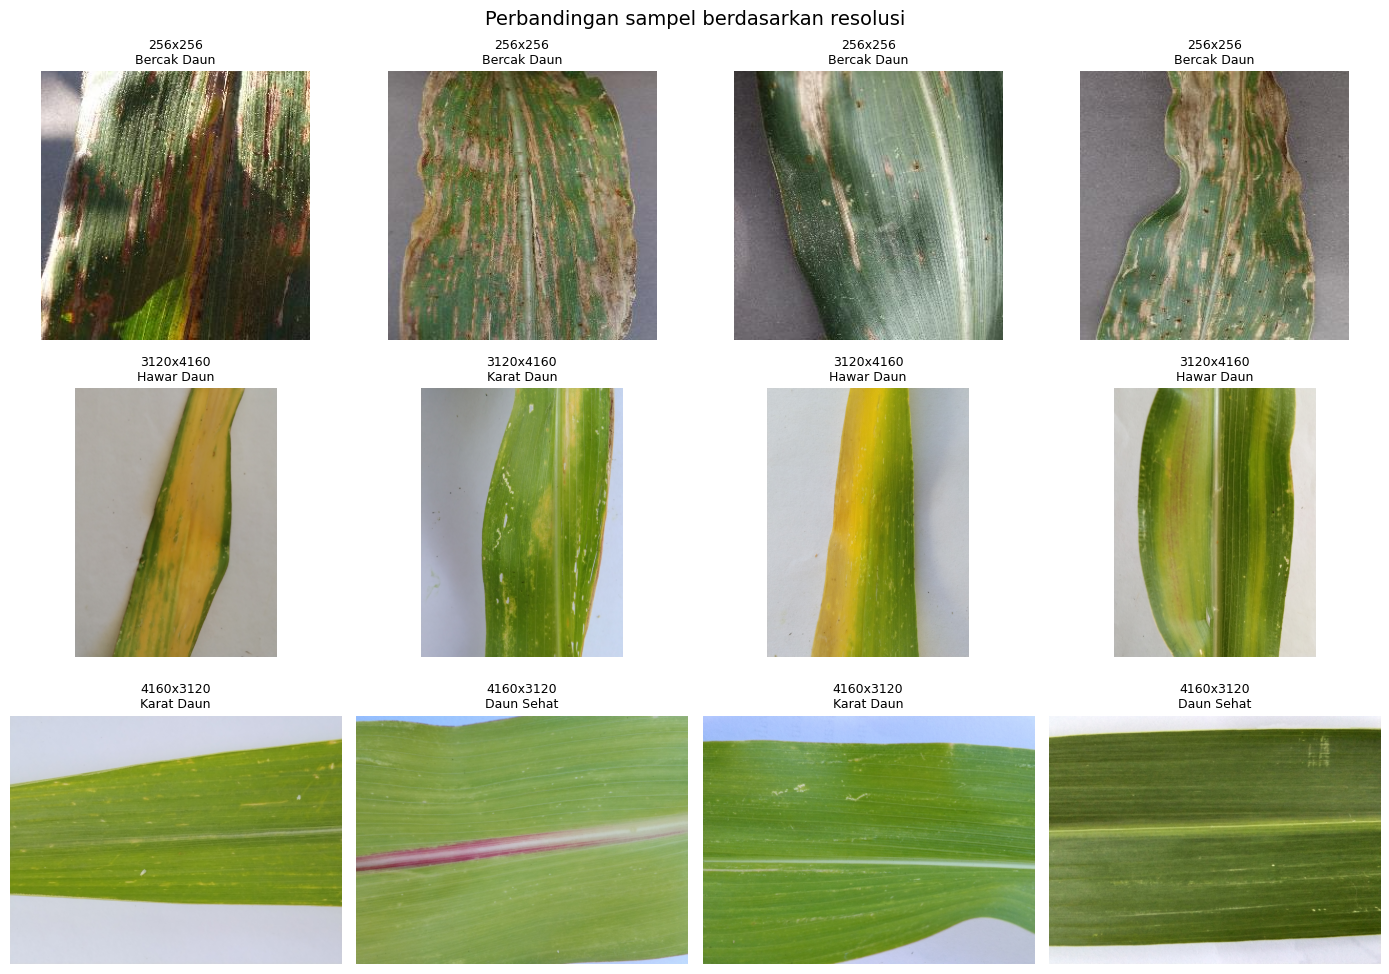

In [6]:

# Cell 3.4 - Visualisasi sampel berdasarkan kelompok resolusi

resolusi_utama = [
    "256x256",
    "3120x4160",
    "4160x3120"
]

fig, axes = plt.subplots(
    len(resolusi_utama),
    4,
    figsize=(14, 10)
)

for i, resolusi in enumerate(resolusi_utama):
    data_resolusi = df_audit[
        df_audit["resolusi"] == resolusi
    ]

    jumlah = min(4, len(data_resolusi))

    if jumlah == 0:
        continue

    sampel = data_resolusi.sample(
        n=jumlah,
        random_state=SEED
    )

    for j in range(4):
        ax = axes[i, j]
        ax.axis("off")

        if j < jumlah:
            baris = sampel.iloc[j]

            with Image.open(baris["path"]) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(
                f"{resolusi}\n"
                f"{baris['folder_induk']}",
                fontsize=9
            )

plt.suptitle(
    "Perbandingan sampel berdasarkan resolusi",
    fontsize=14
)

plt.tight_layout()
plt.show()


1. Distribusi kelas seimbang: ada 1.000 gambar per kelas, tetapi distribusi resolusi sangat tidak seimbang.

2. Bercak Daun berbeda dari kelas lainnya: 926 gambar berukuran 256 × 256 dan 74 gambar beresolusi lain; tidak ada gambar kelas ini pada resolusi 3120 × 4160 atau 4160 × 3120.

3. Tiga kelas lainnya didominasi gambar kamera beresolusi tinggi: Daun Sehat, Hawar Daun, dan Karat Daun seluruhnya memiliki gambar beresolusi tinggi.

4. Nama file menunjukkan dua kelompok yang berbeda: kelas Bercak Daun berisi nama Corn dan augmented, sementara tiga kelas lain menggunakan nama IMG.

5. Ditemukan 6 salinan identik tambahan: 4.000 file hanya memiliki 3.994 hash unik. Enam salinan tambahan tersebut perlu ditangani sebelum pembagian data.

6. Segmentasi layak diuji: karena kondisi background bervariasi, tetapi kita belum boleh menganggap segmentasi otomatis pasti meningkatkan akurasi.

In [7]:

# Cell 4.1 - Memeriksa duplikasi lintas kelas

df_hash_audit = df_hash.merge(
    df_audit[["path", "folder_induk", "resolusi"]],
    on="path",
    how="left"
)

kelompok_duplikat = df_hash_audit[
    df_hash_audit.duplicated("hash", keep=False)
].sort_values(["hash", "folder_induk"])

print("File yang terlibat dalam kelompok duplikat:")
display(
    kelompok_duplikat[
        ["nama_file", "folder_induk", "resolusi", "hash"]
    ] if "nama_file" in kelompok_duplikat.columns
    else kelompok_duplikat[
        ["path", "folder_induk", "resolusi", "hash"]
    ]
)

print("\nJumlah kelas berbeda dalam setiap kelompok duplikat:")

ringkasan_duplikat = (
    kelompok_duplikat.groupby("hash")
    .agg(
        jumlah_file=("path", "size"),
        jumlah_kelas=("folder_induk", "nunique"),
        kelas=("folder_induk", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

display(ringkasan_duplikat)

if (ringkasan_duplikat["jumlah_kelas"] > 1).any():
    print(
        "PERHATIAN: Ada gambar identik yang memiliki label berbeda. "
        "Jangan langsung menghapus atau menetapkan label sebelum "
        "kasus ini diperiksa."
    )
else:
    print(
        "Semua kelompok duplikat memiliki label kelas yang sama."
    )

File yang terlibat dalam kelompok duplikat:


,path,folder_induk,resolusi,hash
2477,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,3c0c4ac278a108128a808f8e5d3ffd0007135064921cf1...
2779,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,3c0c4ac278a108128a808f8e5d3ffd0007135064921cf1...
2875,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,85bcad6305bd99d81ea50a6594aca04d499dedf0a10099...
2951,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,85bcad6305bd99d81ea50a6594aca04d499dedf0a10099...
2125,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,87054230c452db6942e840d2ee365792499f353345b980...
2657,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,87054230c452db6942e840d2ee365792499f353345b980...
2758,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,deeca9920bc488b02b5ae606b25c60d24802e105a180dc...
2941,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,deeca9920bc488b02b5ae606b25c60d24802e105a180dc...
2291,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,e29237f06e7841d6ffd292f0b20ab867c71ffe5d492ba6...
2635,/root/.cache/kagglehub/datasets/ndisan/corn-le...,Karat Daun,4160x3120,e29237f06e7841d6ffd292f0b20ab867c71ffe5d492ba6...



Jumlah kelas berbeda dalam setiap kelompok duplikat:


,hash,jumlah_file,jumlah_kelas,kelas
0,3c0c4ac278a108128a808f8e5d3ffd0007135064921cf1...,2,1,Karat Daun
1,85bcad6305bd99d81ea50a6594aca04d499dedf0a10099...,2,1,Karat Daun
2,87054230c452db6942e840d2ee365792499f353345b980...,2,1,Karat Daun
3,deeca9920bc488b02b5ae606b25c60d24802e105a180dc...,2,1,Karat Daun
4,e29237f06e7841d6ffd292f0b20ab867c71ffe5d492ba6...,2,1,Karat Daun
5,f9bb8052c090a5e3c54ca3fa77f1bceabcade7b0123d32...,2,1,Karat Daun


Semua kelompok duplikat memiliki label kelas yang sama.


Ukuran asli: (4160, 3120, 3)
Ukuran setelah resize: (256, 256, 3)


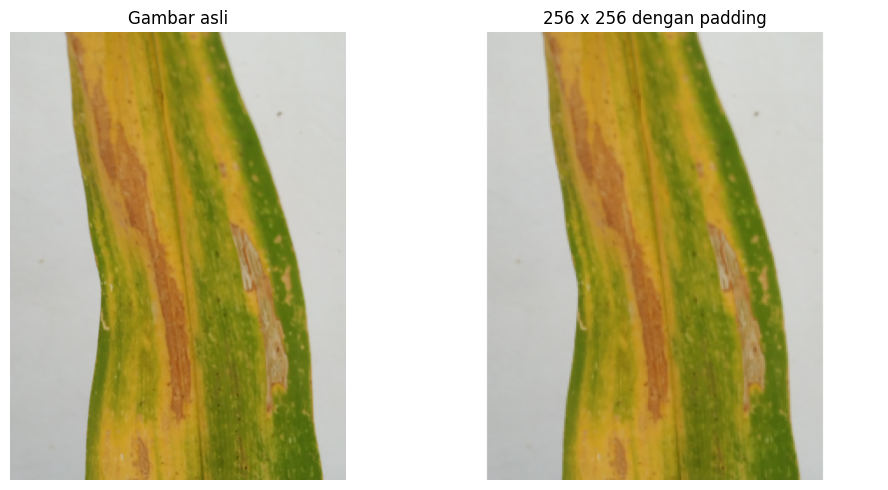

In [8]:

# Cell 4.2 - Fungsi resize dengan mempertahankan rasio aspek

def resize_dengan_padding(img, ukuran=256):
    tinggi, lebar = img.shape[:2]

    skala = ukuran / max(tinggi, lebar)

    lebar_baru = max(1, round(lebar * skala))
    tinggi_baru = max(1, round(tinggi * skala))

    img_kecil = cv2.resize(
        img,
        (lebar_baru, tinggi_baru),
        interpolation=cv2.INTER_AREA
    )

    # Kanvas dengan ukuran tetap
    kanvas = np.full(
        (ukuran, ukuran, 3),
        255,
        dtype=np.uint8
    )

    x_awal = (ukuran - lebar_baru) // 2
    y_awal = (ukuran - tinggi_baru) // 2

    kanvas[
        y_awal:y_awal + tinggi_baru,
        x_awal:x_awal + lebar_baru
    ] = img_kecil

    return kanvas


# Contoh pengujian pada gambar dengan resolusi tinggi
contoh_path = df_audit[
    df_audit["resolusi"] == "3120x4160"
].iloc[0]["path"]

img_asli = cv2.imread(contoh_path)

if img_asli is None:
    raise ValueError("Gambar contoh gagal dibaca oleh OpenCV.")

img_resize = resize_dengan_padding(img_asli, ukuran=256)

print("Ukuran asli:", img_asli.shape)
print("Ukuran setelah resize:", img_resize.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB))
axes[0].set_title("Gambar asli")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB))
axes[1].set_title("256 x 256 dengan padding")
axes[1].axis("off")

plt.tight_layout()
plt.show()

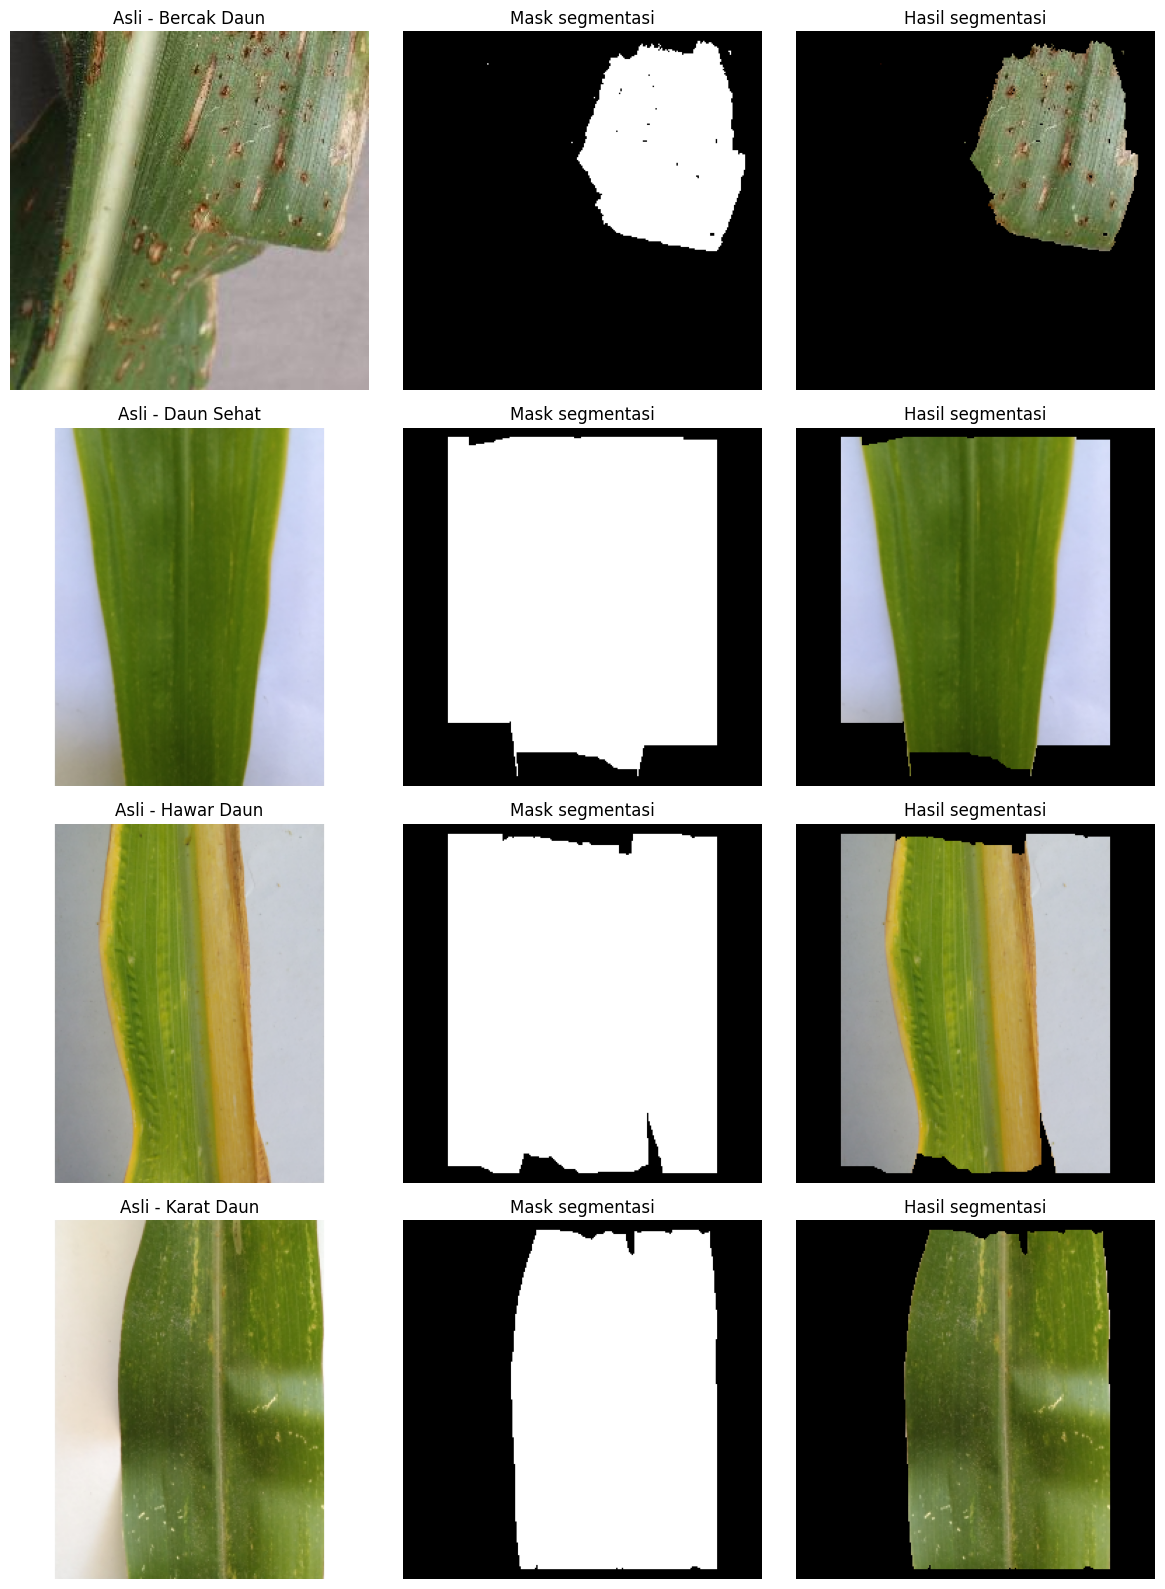

In [9]:

# Cell 4.3 - Uji segmentasi awal pada beberapa gambar

def segmentasi_grabcut(img_bgr):
    tinggi, lebar = img_bgr.shape[:2]

    # Inisialisasi area foreground di bagian dalam gambar
    margin_x = max(1, int(lebar * 0.03))
    margin_y = max(1, int(tinggi * 0.03))

    mask = np.zeros((tinggi, lebar), np.uint8)

    rect = (
        margin_x,
        margin_y,
        max(1, lebar - 2 * margin_x),
        max(1, tinggi - 2 * margin_y)
    )

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr,
        mask,
        rect,
        bg_model,
        fg_model,
        5,
        cv2.GC_INIT_WITH_RECT
    )

    mask_daun = np.where(
        (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    hasil = cv2.bitwise_and(
        img_bgr,
        img_bgr,
        mask=mask_daun
    )

    return mask_daun, hasil


# Ambil sampel dari setiap kelas, dengan seed tetap
sampel_segmentasi = (
    df_audit.groupby("folder_induk", group_keys=False)
    .sample(n=1, random_state=SEED)
)

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i, (_, baris) in enumerate(sampel_segmentasi.iterrows()):
    img = cv2.imread(baris["path"])

    if img is None:
        continue

    # Perkecil dahulu agar pengujian lebih ringan
    img_kecil = resize_dengan_padding(img, ukuran=256)

    mask, hasil = segmentasi_grabcut(img_kecil)

    axes[i, 0].imshow(
        cv2.cvtColor(img_kecil, cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title(
        f"Asli - {baris['folder_induk']}"
    )

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Mask segmentasi")

    axes[i, 2].imshow(
        cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)
    )
    axes[i, 2].set_title("Hasil segmentasi")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

1. Duplikasi berhasil diidentifikasi: terdapat 6 kelompok pasangan gambar identik, semuanya berada di kelas Karat Daun. Artinya, ada 6 salinan tambahan yang harus dikeluarkan dari dataset agar tidak terjadi kebocoran antara training dan testing.

2. Tidak ada konflik label pada duplikasi: seluruh gambar identik mempunyai label kelas yang sama, sehingga cukup menyimpan satu gambar dari setiap kelompok.

3. Resize berhasil: gambar berukuran 4160 × 3120 dapat diubah menjadi 256 × 256. Namun, kita harus memastikan rasio aspek tetap terjaga, seperti yang dilakukan fungsi resize dengan padding.

4. Segmentasi Bercak Daun: bagian daun terdeteksi, tetapi terdapat beberapa piksel background dan lubang kecil di dalam mask.

5. Segmentasi Daun Sehat: mask terlalu persegi dan mencakup sebagian background. Ini menunjukkan GrabCut belum benar-benar mengikuti kontur daun.

6. Segmentasi Hawar Daun: sebagian besar daun terdeteksi, tetapi terdapat area hitam dan bagian tepi yang kurang sempurna.

7. Segmentasi Karat Daun: hasilnya relatif baik, tetapi beberapa bagian tepi daun masih tidak sempurna.

In [10]:

# Cell 5.1 - Membuat daftar data tanpa duplikasi identik

df_clean = df_audit.merge(
    df_hash[["path", "hash"]],
    on="path",
    how="inner"
).copy()

# Memastikan setiap hash hanya digunakan satu kali
df_clean = (
    df_clean
    .sort_values("path")
    .drop_duplicates(subset="hash", keep="first")
    .reset_index(drop=True)
)

# Label numerik untuk kebutuhan model
kelas_unik = sorted(df_clean["folder_induk"].unique())

label_map = {
    kelas: i for i, kelas in enumerate(kelas_unik)
}

df_clean["label"] = df_clean["folder_induk"].map(label_map)

print("Jumlah gambar sebelum deduplikasi:", len(df_audit))
print("Jumlah gambar setelah deduplikasi:", len(df_clean))

print("\nPemetaan label:")
display(
    pd.DataFrame({
        "kelas": list(label_map.keys()),
        "label": list(label_map.values())
    })
)

print("\nDistribusi kelas setelah deduplikasi:")
display(
    df_clean["folder_induk"]
    .value_counts()
    .sort_index()
    .rename("jumlah")
    .to_frame()
)

# Memastikan tidak ada hash yang terduplikasi
assert df_clean["hash"].is_unique

print("\nPemeriksaan duplikasi berhasil.")

Jumlah gambar sebelum deduplikasi: 4000
Jumlah gambar setelah deduplikasi: 3994

Pemetaan label:


,kelas,label
0,Bercak Daun,0
1,Daun Sehat,1
2,Hawar Daun,2
3,Karat Daun,3



Distribusi kelas setelah deduplikasi:


,jumlah
folder_induk,
Bercak Daun,1000
Daun Sehat,1000
Hawar Daun,1000
Karat Daun,994



Pemeriksaan duplikasi berhasil.


In [11]:

# Cell 5.2 - Pembagian training dan testing

from sklearn.model_selection import train_test_split

X_path = df_clean["path"].to_numpy()
y = df_clean["label"].to_numpy()

indeks = np.arange(len(df_clean))

idx_train, idx_test = train_test_split(
    indeks,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y
)

print("Jumlah data training:", len(idx_train))
print("Jumlah data testing:", len(idx_test))

print("\nDistribusi kelas training:")
display(
    df_clean.iloc[idx_train]["folder_induk"]
    .value_counts()
    .sort_index()
    .rename("jumlah")
    .to_frame()
)

print("\nDistribusi kelas testing:")
display(
    df_clean.iloc[idx_test]["folder_induk"]
    .value_counts()
    .sort_index()
    .rename("jumlah")
    .to_frame()
)

Jumlah data training: 3195
Jumlah data testing: 799

Distribusi kelas training:


,jumlah
folder_induk,
Bercak Daun,800
Daun Sehat,800
Hawar Daun,800
Karat Daun,795



Distribusi kelas testing:


,jumlah
folder_induk,
Bercak Daun,200
Daun Sehat,200
Hawar Daun,200
Karat Daun,199


1. Data bersih: 3.994 gambar, setelah menghilangkan enam salinan identik tambahan.

2. Training: 3.195 gambar (80,0%).

3. Testing: 799 gambar (20,0%).

4. Distribusi kelas tetap relatif seimbang: training memiliki 800, 800, 800, dan 795 gambar; testing memiliki 200, 200, 200, dan 199 gambar.

5. Tidak ada konflik label pada gambar duplikat yang ditemukan sebelumnya, sehingga satu salinan per kelompok dapat dipertahankan.

6. Pemetaan label sudah konsisten: Bercak Daun = 0, Daun Sehat = 1, Hawar Daun = 2, dan Karat Daun = 3.

In [12]:

# Cell 6.1 - Fungsi preprocessing dan ekstraksi fitur

def baca_kanal_v(path, ukuran=256):
    img = cv2.imread(path)

    if img is None:
        raise ValueError(f"Gambar tidak dapat dibaca: {path}")

    # Resize sambil mempertahankan rasio aspek
    img = resize_dengan_padding(img, ukuran=ukuran)

    # OpenCV menggunakan urutan warna BGR
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # Ambil kanal V saja
    kanal_v = hsv[:, :, 2]

    return kanal_v


def fitur_baseline_v(kanal_v):
    # Baseline menggunakan resolusi 64 x 64
    v_kecil = cv2.resize(
        kanal_v,
        (64, 64),
        interpolation=cv2.INTER_AREA
    )

    return v_kecil.astype(np.float32).flatten() / 255.0


def statistik_subband(subband):
    subband = np.asarray(subband, dtype=np.float32)

    return [
        float(np.mean(subband)),
        float(np.std(subband)),
        float(np.mean(np.abs(subband))),
        float(np.sqrt(np.mean(subband ** 2)))
    ]


def fitur_wavelet(kanal_v, nama_wavelet, level):
    # Ubah V ke rentang 0-1
    v = kanal_v.astype(np.float32) / 255.0

    # Dekomposisi wavelet 2D
    koef = pywt.wavedec2(
        v,
        wavelet=nama_wavelet,
        level=level,
        mode="symmetric"
    )

    fitur = []

    # Koefisien aproksimasi pada level tertinggi
    fitur.extend(statistik_subband(koef[0]))

    # Koefisien detail: horizontal, vertikal, diagonal
    for detail in koef[1:]:
        for subband in detail:
            fitur.extend(statistik_subband(subband))

    return np.array(fitur, dtype=np.float32)


# Uji fungsi pada satu gambar
contoh_v = baca_kanal_v(df_clean.iloc[0]["path"])

print("Ukuran kanal V:", contoh_v.shape)
print("Jumlah fitur baseline:", len(fitur_baseline_v(contoh_v)))

for nama in ["haar", "db4", "coif1"]:
    for level in [1, 2, 3]:
        hasil = fitur_wavelet(contoh_v, nama, level)

        print(
            f"Wavelet: {nama:5s} | "
            f"Level: {level} | "
            f"Jumlah fitur: {len(hasil)}"
        )

Ukuran kanal V: (256, 256)
Jumlah fitur baseline: 4096
Wavelet: haar  | Level: 1 | Jumlah fitur: 16
Wavelet: haar  | Level: 2 | Jumlah fitur: 28
Wavelet: haar  | Level: 3 | Jumlah fitur: 40
Wavelet: db4   | Level: 1 | Jumlah fitur: 16
Wavelet: db4   | Level: 2 | Jumlah fitur: 28
Wavelet: db4   | Level: 3 | Jumlah fitur: 40
Wavelet: coif1 | Level: 1 | Jumlah fitur: 16
Wavelet: coif1 | Level: 2 | Jumlah fitur: 28
Wavelet: coif1 | Level: 3 | Jumlah fitur: 40


In [13]:

# Cell 6.2 - Ekstraksi fitur untuk seluruh dataset

mulai = time.perf_counter()

fitur_semua = {
    "V_baseline": [],
    "haar_L1": [],
    "haar_L2": [],
    "haar_L3": [],
    "db4_L1": [],
    "db4_L2": [],
    "db4_L3": [],
    "coif1_L1": [],
    "coif1_L2": [],
    "coif1_L3": []
}

label_semua = []
path_semua = []

for i, row in df_clean.iterrows():
    path = row["path"]

    try:
        v = baca_kanal_v(path, ukuran=256)

        fitur_semua["V_baseline"].append(
            fitur_baseline_v(v)
        )

        for nama in ["haar", "db4", "coif1"]:
            for level in [1, 2, 3]:
                nama_fitur = f"{nama}_L{level}"

                fitur_semua[nama_fitur].append(
                    fitur_wavelet(v, nama, level)
                )

        label_semua.append(row["label"])
        path_semua.append(path)

    except Exception as e:
        print("Gagal memproses:", path)
        print("Penyebab:", e)

    if (len(label_semua)) % 250 == 0:
        print(
            f"Berhasil diproses: {len(label_semua)} "
            f"dari {len(df_clean)} gambar"
        )

waktu_ekstraksi = time.perf_counter() - mulai

# Ubah setiap daftar menjadi array NumPy
for nama in fitur_semua:
    fitur_semua[nama] = np.asarray(
        fitur_semua[nama],
        dtype=np.float32
    )

y_fitur = np.asarray(label_semua)
path_fitur = np.asarray(path_semua)

print("\nEkstraksi fitur selesai.")
print("Jumlah gambar berhasil:", len(y_fitur))
print("Waktu total ekstraksi:", round(waktu_ekstraksi, 2), "detik")

print("\nDimensi setiap fitur:")

for nama, X in fitur_semua.items():
    print(f"{nama:12s}: {X.shape}")

Berhasil diproses: 250 dari 3994 gambar
Berhasil diproses: 500 dari 3994 gambar
Berhasil diproses: 750 dari 3994 gambar
Berhasil diproses: 1000 dari 3994 gambar
Berhasil diproses: 1250 dari 3994 gambar
Berhasil diproses: 1500 dari 3994 gambar
Berhasil diproses: 1750 dari 3994 gambar
Berhasil diproses: 2000 dari 3994 gambar
Berhasil diproses: 2250 dari 3994 gambar
Berhasil diproses: 2500 dari 3994 gambar
Berhasil diproses: 2750 dari 3994 gambar
Berhasil diproses: 3000 dari 3994 gambar
Berhasil diproses: 3250 dari 3994 gambar
Berhasil diproses: 3500 dari 3994 gambar
Berhasil diproses: 3750 dari 3994 gambar

Ekstraksi fitur selesai.
Jumlah gambar berhasil: 3994
Waktu total ekstraksi: 618.07 detik

Dimensi setiap fitur:
V_baseline  : (3994, 4096)
haar_L1     : (3994, 16)
haar_L2     : (3994, 28)
haar_L3     : (3994, 40)
db4_L1      : (3994, 16)
db4_L2      : (3994, 28)
db4_L3      : (3994, 40)
coif1_L1    : (3994, 16)
coif1_L2    : (3994, 28)
coif1_L3    : (3994, 40)


In [14]:

# Cell 6.3 - Validasi fitur

print("Jumlah label hasil ekstraksi:", len(y_fitur))
print("Jumlah path hasil ekstraksi:", len(path_fitur))

for nama, X in fitur_semua.items():
    print(f"\n{nama}")
    print("Shape:", X.shape)
    print("Semua nilai finite:", np.isfinite(X).all())
    print("Nilai minimum:", float(np.min(X)))
    print("Nilai maksimum:", float(np.max(X)))

# Pastikan semua konfigurasi menggunakan urutan gambar yang sama
assert len(set(path_fitur)) == len(path_fitur)

for nama, X in fitur_semua.items():
    assert X.shape[0] == len(y_fitur)

print("\nValidasi dasar fitur berhasil.")

Jumlah label hasil ekstraksi: 3994
Jumlah path hasil ekstraksi: 3994

V_baseline
Shape: (3994, 4096)
Semua nilai finite: True
Nilai minimum: 0.0
Nilai maksimum: 1.0

haar_L1
Shape: (3994, 16)
Semua nilai finite: True
Nilai minimum: -0.006467691622674465
Nilai maksimum: 1.8670876026153564

haar_L2
Shape: (3994, 28)
Semua nilai finite: True
Nilai minimum: -0.013708256185054779
Nilai maksimum: 3.7332277297973633

haar_L3
Shape: (3994, 40)
Semua nilai finite: True
Nilai minimum: -0.06645172089338303
Nilai maksimum: 7.463889122009277

db4_L1
Shape: (3994, 16)
Semua nilai finite: True
Nilai minimum: -0.006340702064335346
Nilai maksimum: 1.8686909675598145

db4_L2
Shape: (3994, 28)
Semua nilai finite: True
Nilai minimum: -0.01888127252459526
Nilai maksimum: 3.743440628051758

db4_L3
Shape: (3994, 40)
Semua nilai finite: True
Nilai minimum: -0.06547685712575912
Nilai maksimum: 7.510800361633301

coif1_L1
Shape: (3994, 16)
Semua nilai finite: True
Nilai minimum: -0.006391736678779125
Nilai maks

1. Waktu ekstraksi: 618,07 detik, atau sekitar 10 menit 18 detik untuk seluruh konfigurasi.

2. Baseline V: menghasilkan 4.096 fitur per gambar dari citra 64 × 64.

3. Wavelet: menghasilkan 16 fitur pada level 1, 28 pada level 2, dan 40 pada level 3.

4. Validasi numerik: seluruh nilai fitur finite, tidak ditemukan NaN atau infinity.

5. Kesesuaian data: jumlah baris pada semua matriks fitur sama dengan jumlah label dan path.

In [15]:

# Cell 7.1 - Import library dan siapkan baseline

import time
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Gunakan indeks dari fitur yang benar-benar berhasil diekstrak
idx = np.arange(len(y_fitur))

idx_train, idx_test = train_test_split(
    idx,
    test_size=0.2,
    random_state=42,
    stratify=y_fitur
)

X_train = fitur_semua["V_baseline"][idx_train]
X_test = fitur_semua["V_baseline"][idx_test]

y_train = y_fitur[idx_train]
y_test = y_fitur[idx_test]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Jumlah fold  :", cv.get_n_splits())
print("Jumlah kelas :", len(np.unique(y_train)))

Shape X_train: (3195, 4096)
Shape X_test : (799, 4096)
Jumlah fold  : 5
Jumlah kelas : 4


In [16]:

# Cell 7.2 - Eksperimen baseline

model_baseline = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            weights="uniform",
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

hasil_baseline = []
model_terlatih = {}

for nama, model in model_baseline.items():
    print(f"\nMemproses model: {nama}")

    # 1. Cross-validation hanya pada training set
    mulai_cv = time.perf_counter()

    skor_cv = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    waktu_cv = time.perf_counter() - mulai_cv

    # 2. Training final menggunakan seluruh training set
    mulai_train = time.perf_counter()
    model.fit(X_train, y_train)
    waktu_train = time.perf_counter() - mulai_train

    # 3. Prediksi training dan testing
    mulai_pred = time.perf_counter()
    pred_train = model.predict(X_train)
    waktu_pred_train = time.perf_counter() - mulai_pred

    mulai_pred = time.perf_counter()
    pred_test = model.predict(X_test)
    waktu_pred_test = time.perf_counter() - mulai_pred

    # 4. Simpan model untuk analisis berikutnya
    model_terlatih[nama] = model

    hasil_baseline.append({
        "Model": nama,
        "CV_mean": skor_cv.mean(),
        "CV_std": skor_cv.std(),
        "Train_accuracy": accuracy_score(y_train, pred_train),
        "Test_accuracy": accuracy_score(y_test, pred_test),
        "Test_precision_macro": precision_score(
            y_test, pred_test, average="macro", zero_division=0
        ),
        "Test_recall_macro": recall_score(
            y_test, pred_test, average="macro", zero_division=0
        ),
        "Test_F1_macro": f1_score(
            y_test, pred_test, average="macro", zero_division=0
        ),
        "CV_time_sec": waktu_cv,
        "Train_time_sec": waktu_train,
        "Predict_train_sec": waktu_pred_train,
        "Predict_test_sec": waktu_pred_test
    })

    print("CV accuracy tiap fold:", np.round(skor_cv, 4))
    print("Rata-rata CV:", round(skor_cv.mean(), 4))
    print("Akurasi training:", round(
        accuracy_score(y_train, pred_train), 4
    ))
    print("Akurasi testing:", round(
        accuracy_score(y_test, pred_test), 4
    ))
    print("Waktu CV (detik):", round(waktu_cv, 2))
    print("Waktu training final (detik):", round(waktu_train, 2))
    print("Waktu prediksi testing (detik):", round(waktu_pred_test, 4))

df_hasil_baseline = pd.DataFrame(hasil_baseline)

print("\nTabel hasil baseline:")
display(
    df_hasil_baseline.round(4)
)


Memproses model: KNN
CV accuracy tiap fold: [0.7418 0.7574 0.7293 0.7152 0.7496]
Rata-rata CV: 0.7387
Akurasi training: 0.8056
Akurasi testing: 0.7322
Waktu CV (detik): 3.91
Waktu training final (detik): 0.39
Waktu prediksi testing (detik): 0.8106

Memproses model: SVM
CV accuracy tiap fold: [0.7887 0.8028 0.7903 0.8044 0.7919]
Rata-rata CV: 0.7956
Akurasi training: 0.8648
Akurasi testing: 0.8098
Waktu CV (detik): 84.68
Waktu training final (detik): 18.36
Waktu prediksi testing (detik): 7.5684

Memproses model: Random Forest
CV accuracy tiap fold: [0.8122 0.831  0.8106 0.8263 0.8326]
Rata-rata CV: 0.8225
Akurasi training: 1.0
Akurasi testing: 0.831
Waktu CV (detik): 70.54
Waktu training final (detik): 17.47
Waktu prediksi testing (detik): 0.0777

Tabel hasil baseline:


,Model,CV_mean,CV_std,Train_accuracy,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_F1_macro,CV_time_sec,Train_time_sec,Predict_train_sec,Predict_test_sec
0,KNN,0.7387,0.0150,0.8056,0.7322,0.7580,0.7317,0.7232,3.9083,0.3946,5.4582,0.8106
1,SVM,0.7956,0.0066,0.8648,0.8098,0.8156,0.8096,0.8120,84.6835,18.3611,29.5784,7.5684
2,Random Forest,0.8225,0.0093,1.0000,0.8310,0.8335,0.8309,0.8320,70.5384,17.4712,0.1979,0.0777


In [17]:

# Cell 7.3 - Evaluasi detail setiap model

nama_kelas = [
    kelas for kelas, label in sorted(
        label_map.items(), key=lambda item: item[1]
    )
]

for nama, model in model_terlatih.items():
    pred_test = model.predict(X_test)

    print("\n" + "=" * 60)
    print("MODEL:", nama)
    print("=" * 60)

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            pred_test,
            labels=np.arange(len(nama_kelas)),
            target_names=nama_kelas,
            digits=4,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        pred_test,
        labels=np.arange(len(nama_kelas))
    )

    cm_df = pd.DataFrame(
        cm,
        index=nama_kelas,
        columns=nama_kelas
    )

    print("Confusion matrix (baris = aktual, kolom = prediksi):")
    display(cm_df)


MODEL: KNN

Classification report:
              precision    recall  f1-score   support

 Bercak Daun     1.0000    0.9100    0.9529       200
  Daun Sehat     0.5600    0.9100    0.6933       200
  Hawar Daun     0.8232    0.7450    0.7822       200
  Karat Daun     0.6486    0.3618    0.4645       199

    accuracy                         0.7322       799
   macro avg     0.7580    0.7317    0.7232       799
weighted avg     0.7581    0.7322    0.7235       799

Confusion matrix (baris = aktual, kolom = prediksi):


,Bercak Daun,Daun Sehat,Hawar Daun,Karat Daun
Bercak Daun,182,11,6,1
Daun Sehat,0,182,5,13
Hawar Daun,0,26,149,25
Karat Daun,0,106,21,72



MODEL: SVM

Classification report:
              precision    recall  f1-score   support

 Bercak Daun     1.0000    0.9550    0.9770       200
  Daun Sehat     0.7846    0.7650    0.7747       200
  Hawar Daun     0.8247    0.8000    0.8122       200
  Karat Daun     0.6530    0.7186    0.6842       199

    accuracy                         0.8098       799
   macro avg     0.8156    0.8096    0.8120       799
weighted avg     0.8158    0.8098    0.8122       799

Confusion matrix (baris = aktual, kolom = prediksi):


,Bercak Daun,Daun Sehat,Hawar Daun,Karat Daun
Bercak Daun,191,5,2,2
Daun Sehat,0,153,5,42
Hawar Daun,0,8,160,32
Karat Daun,0,29,27,143



MODEL: Random Forest

Classification report:
              precision    recall  f1-score   support

 Bercak Daun     1.0000    0.9550    0.9770       200
  Daun Sehat     0.7885    0.8200    0.8039       200
  Hawar Daun     0.8291    0.8250    0.8271       200
  Karat Daun     0.7164    0.7236    0.7200       199

    accuracy                         0.8310       799
   macro avg     0.8335    0.8309    0.8320       799
weighted avg     0.8337    0.8310    0.8321       799

Confusion matrix (baris = aktual, kolom = prediksi):


,Bercak Daun,Daun Sehat,Hawar Daun,Karat Daun
Bercak Daun,191,4,3,2
Daun Sehat,0,164,6,30
Hawar Daun,0,10,165,25
Karat Daun,0,30,25,144


1. Random Forest adalah baseline terbaik berdasarkan testing accuracy dan F1 macro.

2. KNN mengalami kesulitan membedakan Karat Daun dari Daun Sehat. Recall Karat Daun hanya 36,18%, dengan 106 dari 199 gambar Karat Daun salah diprediksi sebagai Daun Sehat.

3. SVM memperbaiki recall Karat Daun menjadi 71,86%, tetapi masih salah mengklasifikasikan 42 gambar Daun Sehat sebagai Karat Daun.

4. Random Forest memberikan hasil paling seimbang di antara ketiga model, meskipun akurasi training 100% menunjukkan indikasi overfitting.

5. Akurasi cross-validation dan testing Random Forest relatif berdekatan, yaitu 82,25% dan 83,10%. Ini tidak membuktikan tidak adanya overfitting; selisih akurasi training-test yang besar tetap perlu diperhatikan.

kelas Bercak Daun memperoleh skor sangat tinggi pada ketiga model. Karena kelas ini berasal dari sumber dan pola resolusi yang berbeda, sebagian keberhasilan tersebut mungkin dipengaruhi karakteristik sumber gambar, bukan hanya ciri penyakit.

In [18]:

# Cell 8.1 - Menggabungkan fitur V dan statistik wavelet

fitur_gabungan = {}

for nama_wavelet in ["haar", "db4", "coif1"]:
    for level in [1, 2, 3]:

        nama_fitur = f"{nama_wavelet}_L{level}"

        X_v = fitur_semua["V_baseline"]
        X_w = fitur_semua[nama_fitur]

        # Gabungkan fitur V dan statistik wavelet
        fitur_gabungan[nama_fitur] = np.hstack(
            (X_v, X_w)
        ).astype(np.float32)

        print(
            f"{nama_fitur:10s} | "
            f"Fitur V: {X_v.shape[1]} | "
            f"Fitur wavelet: {X_w.shape[1]} | "
            f"Total: {fitur_gabungan[nama_fitur].shape[1]}"
        )

# Pastikan jumlah sampel dan urutan label konsisten
for nama, X in fitur_gabungan.items():
    assert X.shape[0] == len(y_fitur)
    assert np.isfinite(X).all()

print("\nSemua fitur gabungan berhasil dibuat.")


haar_L1    | Fitur V: 4096 | Fitur wavelet: 16 | Total: 4112
haar_L2    | Fitur V: 4096 | Fitur wavelet: 28 | Total: 4124
haar_L3    | Fitur V: 4096 | Fitur wavelet: 40 | Total: 4136
db4_L1     | Fitur V: 4096 | Fitur wavelet: 16 | Total: 4112
db4_L2     | Fitur V: 4096 | Fitur wavelet: 28 | Total: 4124
db4_L3     | Fitur V: 4096 | Fitur wavelet: 40 | Total: 4136
coif1_L1   | Fitur V: 4096 | Fitur wavelet: 16 | Total: 4112
coif1_L2   | Fitur V: 4096 | Fitur wavelet: 28 | Total: 4124
coif1_L3   | Fitur V: 4096 | Fitur wavelet: 40 | Total: 4136

Semua fitur gabungan berhasil dibuat.


In [19]:

# Cell 8.2 - Evaluasi semua konfigurasi V + wavelet

hasil_wavelet = []
model_wavelet_terlatih = {}

for nama_fitur, X_semua in fitur_gabungan.items():

    print(f"\n{'=' * 55}")
    print("Fitur:", nama_fitur)

    X_train = X_semua[idx_train]
    X_test = X_semua[idx_test]

    y_train = y_fitur[idx_train]
    y_test = y_fitur[idx_test]

    model_uji = {
        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(
                n_neighbors=5,
                weights="uniform",
                n_jobs=-1
            ))
        ]),

        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale"
            ))
        ]),

        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    }

    for nama_model, model in model_uji.items():

        print("Model:", nama_model)

        # Cross-validation hanya pada training set
        mulai = time.perf_counter()

        skor_cv = cross_val_score(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring="accuracy",
            n_jobs=1
        )

        waktu_cv = time.perf_counter() - mulai

        # Training model final
        mulai = time.perf_counter()
        model.fit(X_train, y_train)
        waktu_train = time.perf_counter() - mulai

        # Evaluasi training dan testing
        mulai = time.perf_counter()
        pred_train = model.predict(X_train)
        waktu_pred_train = time.perf_counter() - mulai

        mulai = time.perf_counter()
        pred_test = model.predict(X_test)
        waktu_pred_test = time.perf_counter() - mulai

        hasil_wavelet.append({
            "Fitur": nama_fitur,
            "Model": nama_model,
            "CV_mean": skor_cv.mean(),
            "CV_std": skor_cv.std(),
            "Train_accuracy": accuracy_score(
                y_train, pred_train
            ),
            "Test_accuracy": accuracy_score(
                y_test, pred_test
            ),
            "Test_precision_macro": precision_score(
                y_test, pred_test,
                average="macro",
                zero_division=0
            ),
            "Test_recall_macro": recall_score(
                y_test, pred_test,
                average="macro",
                zero_division=0
            ),
            "Test_F1_macro": f1_score(
                y_test, pred_test,
                average="macro",
                zero_division=0
            ),
            "CV_time_sec": waktu_cv,
            "Train_time_sec": waktu_train,
            "Predict_train_sec": waktu_pred_train,
            "Predict_test_sec": waktu_pred_test
        })

        model_wavelet_terlatih[(nama_fitur, nama_model)] = model

        print(
            f"CV={skor_cv.mean():.4f} "
            f"+/- {skor_cv.std():.4f} | "
            f"Train={accuracy_score(y_train, pred_train):.4f} | "
            f"Test={accuracy_score(y_test, pred_test):.4f} | "
            f"CV time={waktu_cv:.2f}s | "
            f"Train time={waktu_train:.2f}s"
        )

df_hasil_wavelet = pd.DataFrame(hasil_wavelet)

print("\nSemua eksperimen wavelet selesai.")
display(df_hasil_wavelet.round(4))


Fitur: haar_L1
Model: KNN
CV=0.7399 +/- 0.0133 | Train=0.8066 | Test=0.7372 | CV time=3.76s | Train time=0.23s
Model: SVM
CV=0.8003 +/- 0.0072 | Train=0.8695 | Test=0.8173 | CV time=86.38s | Train time=18.07s
Model: Random Forest
CV=0.8779 +/- 0.0059 | Train=1.0000 | Test=0.8773 | CV time=69.37s | Train time=17.77s

Fitur: haar_L2
Model: KNN
CV=0.7393 +/- 0.0137 | Train=0.8078 | Test=0.7384 | CV time=3.84s | Train time=0.22s
Model: SVM
CV=0.8075 +/- 0.0075 | Train=0.8761 | Test=0.8248 | CV time=90.97s | Train time=18.35s
Model: Random Forest
CV=0.8930 +/- 0.0065 | Train=1.0000 | Test=0.8924 | CV time=68.28s | Train time=16.72s

Fitur: haar_L3
Model: KNN
CV=0.7424 +/- 0.0139 | Train=0.8100 | Test=0.7397 | CV time=4.62s | Train time=0.21s
Model: SVM
CV=0.8156 +/- 0.0055 | Train=0.8804 | Test=0.8323 | CV time=85.77s | Train time=17.97s
Model: Random Forest
CV=0.8967 +/- 0.0060 | Train=1.0000 | Test=0.8936 | CV time=68.50s | Train time=16.75s

Fitur: db4_L1
Model: KNN
CV=0.7396 +/- 0.0140

,Fitur,Model,CV_mean,CV_std,Train_accuracy,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_F1_macro,CV_time_sec,Train_time_sec,Predict_train_sec,Predict_test_sec
0,haar_L1,KNN,0.7399,0.0133,0.8066,0.7372,0.7633,0.7367,0.7291,3.7635,0.2256,3.1609,0.8077
1,haar_L1,SVM,0.8003,0.0072,0.8695,0.8173,0.8229,0.8172,0.8194,86.3752,18.0749,30.4330,7.1438
2,haar_L1,Random Forest,0.8779,0.0059,1.0000,0.8773,0.8785,0.8773,0.8778,69.3724,17.7650,0.3666,0.1479
3,haar_L2,KNN,0.7393,0.0137,0.8078,0.7384,0.7651,0.7380,0.7301,3.8398,0.2177,3.1072,0.7978
4,haar_L2,SVM,0.8075,0.0075,0.8761,0.8248,0.8308,0.8247,0.8270,90.9674,18.3524,30.0465,7.0383
5,haar_L2,Random Forest,0.8930,0.0065,1.0000,0.8924,0.8926,0.8923,0.8924,68.2797,16.7180,0.1874,0.0815
6,haar_L3,KNN,0.7424,0.0139,0.8100,0.7397,0.7666,0.7392,0.7312,4.6205,0.2093,3.1015,0.8029
7,haar_L3,SVM,0.8156,0.0055,0.8804,0.8323,0.8382,0.8322,0.8343,85.7711,17.9727,29.2237,7.6818
8,haar_L3,Random Forest,0.8967,0.0060,1.0000,0.8936,0.8944,0.8935,0.8938,68.5034,16.7503,0.1899,0.0790
9,db4_L1,KNN,0.7396,0.0140,0.8063,0.7347,0.7604,0.7342,0.7263,3.5382,0.2035,4.2932,0.8227


In [20]:

# Cell 8.3 - Tabel perbandingan baseline dan wavelet

df_baseline_banding = df_hasil_baseline.copy()
df_baseline_banding["Fitur"] = "V_baseline"

df_perbandingan = pd.concat(
    [df_baseline_banding, df_hasil_wavelet],
    ignore_index=True
)

kolom_hasil = [
    "Fitur",
    "Model",
    "CV_mean",
    "CV_std",
    "Train_accuracy",
    "Test_accuracy",
    "Test_precision_macro",
    "Test_recall_macro",
    "Test_F1_macro",
    "CV_time_sec",
    "Train_time_sec",
    "Predict_test_sec"
]

display(
    df_perbandingan[kolom_hasil]
    .sort_values(
        ["Model", "Test_accuracy"],
        ascending=[True, False]
    )
    .round(4)
    .reset_index(drop=True)
)

# Selisih testing accuracy terhadap baseline model yang sama
baseline_test = (
    df_hasil_baseline
    .set_index("Model")["Test_accuracy"]
    .to_dict()
)

df_perbandingan["Delta_test_vs_baseline"] = (
    df_perbandingan.apply(
        lambda row: (
            row["Test_accuracy"] -
            baseline_test[row["Model"]]
        ),
        axis=1
    )
)

print("\nPerubahan akurasi testing terhadap baseline:")
display(
    df_perbandingan[
        ["Fitur", "Model", "Test_accuracy",
         "Delta_test_vs_baseline"]
    ]
    .sort_values("Delta_test_vs_baseline", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Fitur,Model,CV_mean,CV_std,Train_accuracy,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_F1_macro,CV_time_sec,Train_time_sec,Predict_test_sec
0,db4_L3,KNN,0.7405,0.0139,0.8085,0.7409,0.7671,0.7405,0.7333,3.5201,0.2056,1.1761
1,haar_L3,KNN,0.7424,0.0139,0.8100,0.7397,0.7666,0.7392,0.7312,4.6205,0.2093,0.8029
2,haar_L2,KNN,0.7393,0.0137,0.8078,0.7384,0.7651,0.7380,0.7301,3.8398,0.2177,0.7978
3,coif1_L2,KNN,0.7402,0.0142,0.8081,0.7384,0.7651,0.7380,0.7301,3.8245,0.2057,0.8171
4,coif1_L3,KNN,0.7415,0.0135,0.8097,0.7384,0.7648,0.7380,0.7302,4.5563,0.2122,0.7908
5,haar_L1,KNN,0.7399,0.0133,0.8066,0.7372,0.7633,0.7367,0.7291,3.7635,0.2256,0.8077
6,db4_L2,KNN,0.7402,0.0134,0.8069,0.7372,0.7633,0.7367,0.7291,4.6368,0.2054,0.8069
7,coif1_L1,KNN,0.7393,0.0138,0.8059,0.7372,0.7633,0.7367,0.7291,3.5230,0.2045,0.8043
8,db4_L1,KNN,0.7396,0.0140,0.8063,0.7347,0.7604,0.7342,0.7263,3.5382,0.2035,0.8227
9,V_baseline,KNN,0.7387,0.0150,0.8056,0.7322,0.7580,0.7317,0.7232,3.9083,0.3946,0.8106



Perubahan akurasi testing terhadap baseline:


,Fitur,Model,Test_accuracy,Delta_test_vs_baseline
0,coif1_L3,Random Forest,0.8999,0.0688
1,db4_L3,Random Forest,0.8986,0.0676
2,haar_L3,Random Forest,0.8936,0.0626
3,haar_L2,Random Forest,0.8924,0.0613
4,coif1_L2,Random Forest,0.8886,0.0576
5,db4_L2,Random Forest,0.8849,0.0538
6,haar_L1,Random Forest,0.8773,0.0463
7,db4_L1,Random Forest,0.8736,0.0426
8,coif1_L1,Random Forest,0.8723,0.0413
9,db4_L3,SVM,0.8348,0.0250


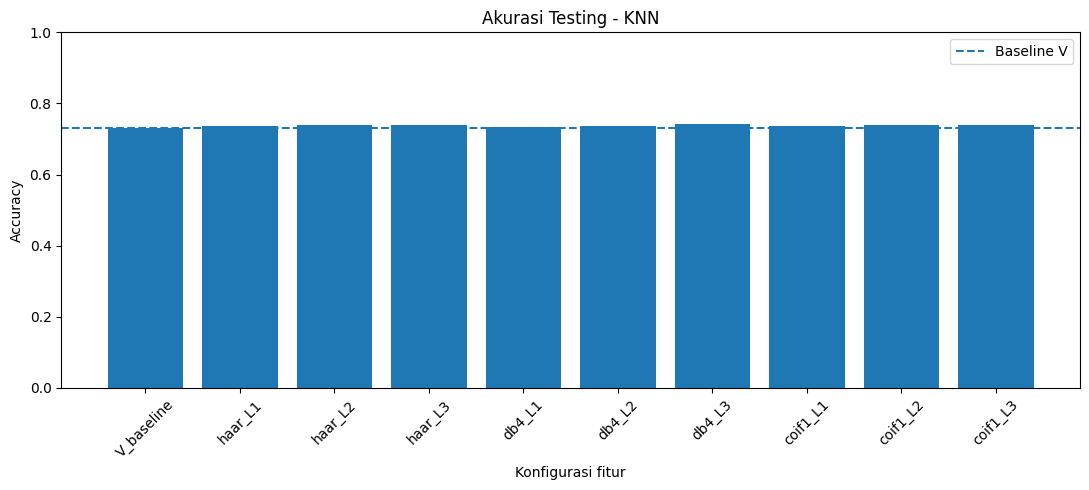

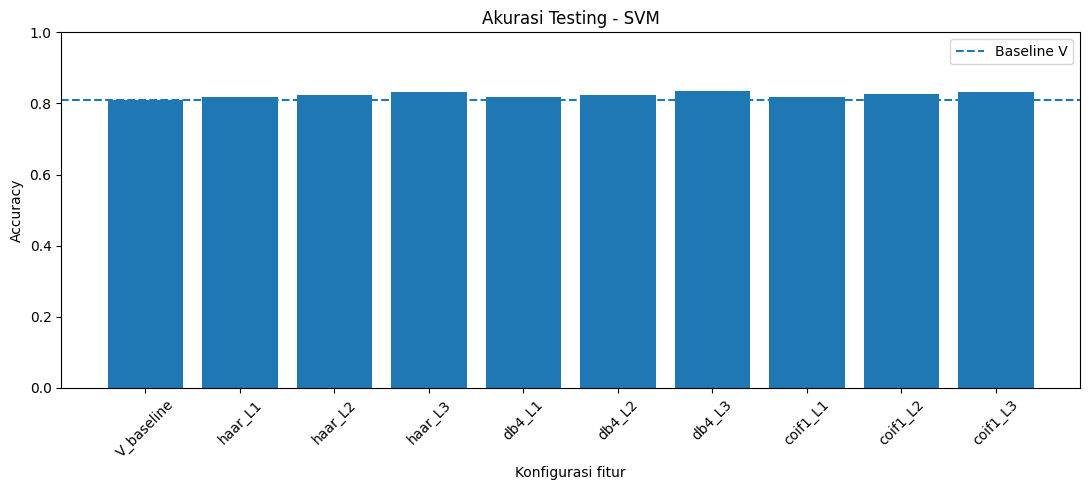

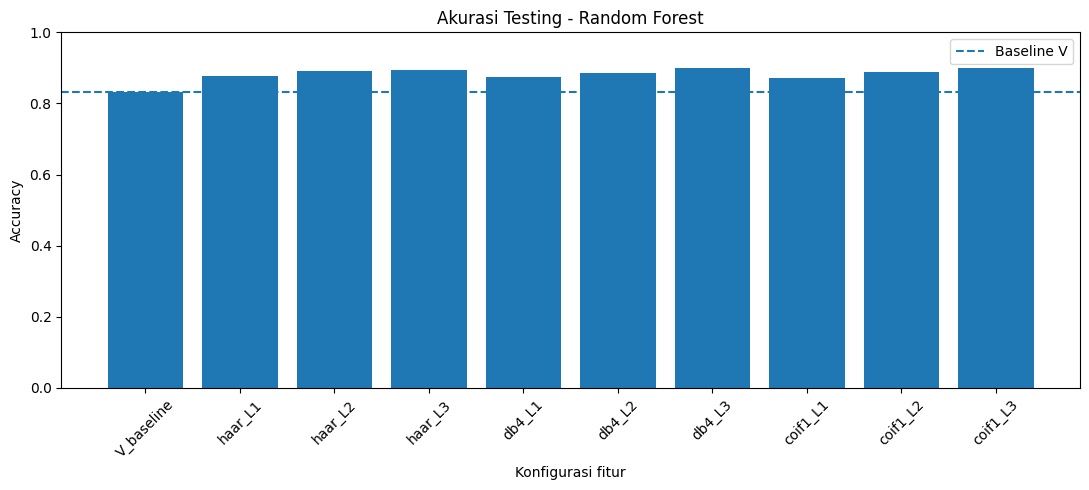

In [21]:

# Cell 8.4 - Grafik perbandingan akurasi testing

urutan_fitur = [
    "V_baseline",
    "haar_L1", "haar_L2", "haar_L3",
    "db4_L1", "db4_L2", "db4_L3",
    "coif1_L1", "coif1_L2", "coif1_L3"
]

for nama_model in ["KNN", "SVM", "Random Forest"]:

    data_plot = (
        df_perbandingan[
            df_perbandingan["Model"] == nama_model
        ]
        .set_index("Fitur")
        .reindex(urutan_fitur)
    )

    plt.figure(figsize=(11, 5))

    plt.bar(
        data_plot.index,
        data_plot["Test_accuracy"]
    )

    plt.axhline(
        baseline_test[nama_model],
        linestyle="--",
        label="Baseline V"
    )

    plt.title(f"Akurasi Testing - {nama_model}")
    plt.ylabel("Accuracy")
    plt.xlabel("Konfigurasi fitur")
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [22]:

# Cell 9.1 - Ringkasan perbandingan seluruh eksperimen

# Ambil kolom yang diperlukan
kolom_ringkas = [
    "Fitur",
    "Model",
    "CV_mean",
    "CV_std",
    "Train_accuracy",
    "Test_accuracy",
    "Test_precision_macro",
    "Test_recall_macro",
    "Test_F1_macro",
    "CV_time_sec",
    "Train_time_sec",
    "Predict_test_sec"
]

tabel_ringkas = df_perbandingan[kolom_ringkas].copy()

# Tambahkan perubahan testing accuracy dari baseline
tabel_ringkas["Delta_test"] = tabel_ringkas.apply(
    lambda baris: (
        baris["Test_accuracy"]
        - baseline_test[baris["Model"]]
    ),
    axis=1
)

# Konversi perubahan ke poin persentase
tabel_ringkas["Delta_test_pp"] = (
    tabel_ringkas["Delta_test"] * 100
)

display(
    tabel_ringkas
    .sort_values(
        ["Model", "CV_mean"],
        ascending=[True, False]
    )
    .round(4)
    .reset_index(drop=True)
)

,Fitur,Model,CV_mean,CV_std,Train_accuracy,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_F1_macro,CV_time_sec,Train_time_sec,Predict_test_sec,Delta_test,Delta_test_pp
0,haar_L3,KNN,0.7424,0.0139,0.8100,0.7397,0.7666,0.7392,0.7312,4.6205,0.2093,0.8029,0.0075,0.7509
1,coif1_L3,KNN,0.7415,0.0135,0.8097,0.7384,0.7648,0.7380,0.7302,4.5563,0.2122,0.7908,0.0063,0.6258
2,db4_L3,KNN,0.7405,0.0139,0.8085,0.7409,0.7671,0.7405,0.7333,3.5201,0.2056,1.1761,0.0088,0.8761
3,db4_L2,KNN,0.7402,0.0134,0.8069,0.7372,0.7633,0.7367,0.7291,4.6368,0.2054,0.8069,0.0050,0.5006
4,coif1_L2,KNN,0.7402,0.0142,0.8081,0.7384,0.7651,0.7380,0.7301,3.8245,0.2057,0.8171,0.0063,0.6258
5,haar_L1,KNN,0.7399,0.0133,0.8066,0.7372,0.7633,0.7367,0.7291,3.7635,0.2256,0.8077,0.0050,0.5006
6,db4_L1,KNN,0.7396,0.0140,0.8063,0.7347,0.7604,0.7342,0.7263,3.5382,0.2035,0.8227,0.0025,0.2503
7,coif1_L1,KNN,0.7393,0.0138,0.8059,0.7372,0.7633,0.7367,0.7291,3.5230,0.2045,0.8043,0.0050,0.5006
8,haar_L2,KNN,0.7393,0.0137,0.8078,0.7384,0.7651,0.7380,0.7301,3.8398,0.2177,0.7978,0.0063,0.6258
9,V_baseline,KNN,0.7387,0.0150,0.8056,0.7322,0.7580,0.7317,0.7232,3.9083,0.3946,0.8106,0.0000,0.0000


In [23]:

# Cell 9.2 - Konfigurasi terbaik berdasarkan rata-rata CV

hasil_terbaik_cv = (
    df_perbandingan
    .sort_values("CV_mean", ascending=False)
    .groupby("Model", as_index=False)
    .first()
)

display(
    hasil_terbaik_cv[
        [
            "Model",
            "Fitur",
            "CV_mean",
            "CV_std",
            "Test_accuracy",
            "Test_F1_macro",
            "Train_time_sec",
            "Predict_test_sec"
        ]
    ].round(4)
)

print("\nKonfigurasi terbaik secara keseluruhan berdasarkan CV:")
display(
    df_perbandingan
    .sort_values("CV_mean", ascending=False)
    .head(5)[
        [
            "Fitur",
            "Model",
            "CV_mean",
            "CV_std",
            "Test_accuracy",
            "Test_F1_macro"
        ]
    ].round(4)
)

,Model,Fitur,CV_mean,CV_std,Test_accuracy,Test_F1_macro,Train_time_sec,Predict_test_sec
0,KNN,haar_L3,0.7424,0.0139,0.7397,0.7312,0.2093,0.8029
1,Random Forest,db4_L3,0.8983,0.0048,0.8986,0.8985,18.2971,0.0812
2,SVM,haar_L3,0.8156,0.0055,0.8323,0.8343,17.9727,7.6818



Konfigurasi terbaik secara keseluruhan berdasarkan CV:


,Fitur,Model,CV_mean,CV_std,Test_accuracy,Test_F1_macro
20,db4_L3,Random Forest,0.8983,0.0048,0.8986,0.8985
11,haar_L3,Random Forest,0.8967,0.0060,0.8936,0.8938
29,coif1_L3,Random Forest,0.8955,0.0052,0.8999,0.9001
8,haar_L2,Random Forest,0.8930,0.0065,0.8924,0.8924
17,db4_L2,Random Forest,0.8920,0.0068,0.8849,0.8854



Model: KNN
Fitur: haar_L3
              precision    recall  f1-score   support

 Bercak Daun     1.0000    0.9100    0.9529       200
  Daun Sehat     0.5679    0.9200    0.7023       200
  Hawar Daun     0.8287    0.7500    0.7874       200
  Karat Daun     0.6696    0.3769    0.4823       199

    accuracy                         0.7397       799
   macro avg     0.7666    0.7392    0.7312       799
weighted avg     0.7667    0.7397    0.7315       799



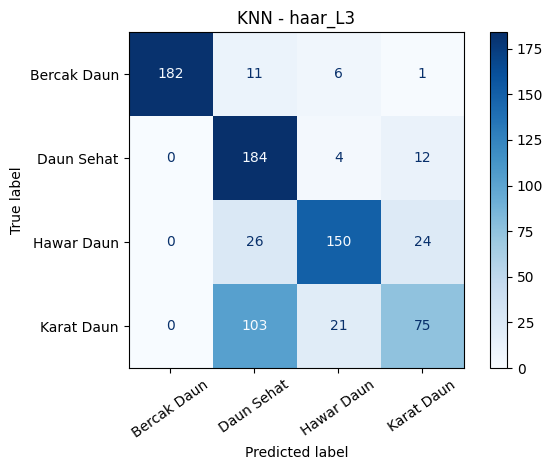


Model: Random Forest
Fitur: db4_L3
              precision    recall  f1-score   support

 Bercak Daun     1.0000    0.9850    0.9924       200
  Daun Sehat     0.9275    0.9600    0.9435       200
  Hawar Daun     0.8717    0.8150    0.8424       200
  Karat Daun     0.7981    0.8342    0.8157       199

    accuracy                         0.8986       799
   macro avg     0.8993    0.8985    0.8985       799
weighted avg     0.8994    0.8986    0.8986       799



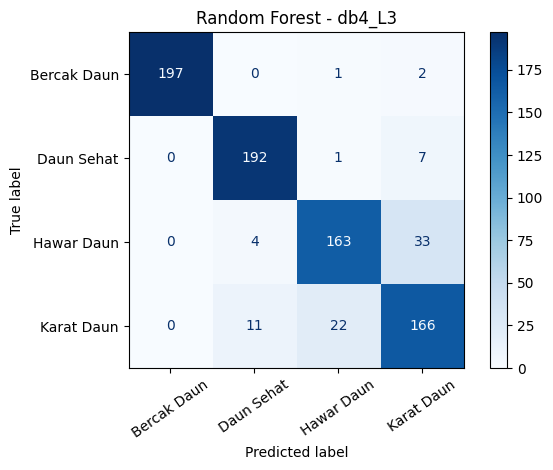


Model: SVM
Fitur: haar_L3
              precision    recall  f1-score   support

 Bercak Daun     1.0000    0.9600    0.9796       200
  Daun Sehat     0.8290    0.8000    0.8142       200
  Hawar Daun     0.8377    0.8000    0.8184       200
  Karat Daun     0.6861    0.7688    0.7251       199

    accuracy                         0.8323       799
   macro avg     0.8382    0.8322    0.8343       799
weighted avg     0.8384    0.8323    0.8345       799



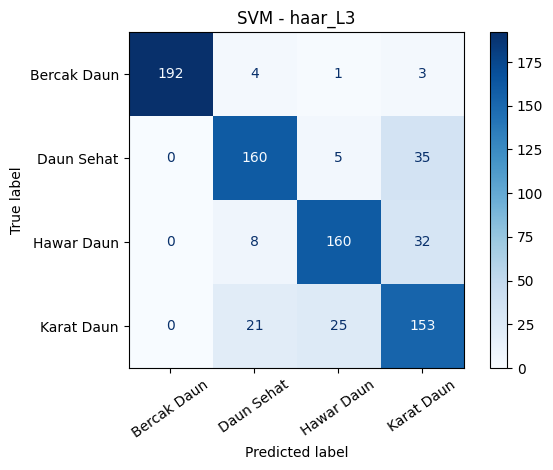

In [24]:

# Cell 9.3 - Evaluasi detail konfigurasi terbaik tiap model

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

nama_kelas = [
    "Bercak Daun",
    "Daun Sehat",
    "Hawar Daun",
    "Karat Daun"
]

for _, baris in hasil_terbaik_cv.iterrows():

    nama_model = baris["Model"]
    nama_fitur = baris["Fitur"]

    # Ambil model terlatih dari eksperimen sebelumnya
    if nama_fitur == "V_baseline":
        model = model_baseline_terlatih[nama_model]
        X_eval = fitur_semua["V_baseline"][idx_test]
    else:
        model = model_wavelet_terlatih[
            (nama_fitur, nama_model)
        ]
        X_eval = fitur_gabungan[nama_fitur][idx_test]

    y_eval = y_fitur[idx_test]
    prediksi = model.predict(X_eval)

    print("\n" + "=" * 60)
    print("Model:", nama_model)
    print("Fitur:", nama_fitur)

    print(
        classification_report(
            y_eval,
            prediksi,
            labels=[0, 1, 2, 3],
            target_names=nama_kelas,
            digits=4,
            zero_division=0
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_eval,
        prediksi,
        labels=[0, 1, 2, 3],
        display_labels=nama_kelas,
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{nama_model} - {nama_fitur}")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()